In [30]:
import pandas as pd
import os
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import matplotlib.patches as patches
from matplotlib.patches import Patch
# Plotting functions
# Keep text editable in AI
mpl.rcParams['pdf.fonttype'] = 42 # embed TrueType fonts in PDF
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['svg.fonttype'] = 'none' # write <text> in SVG (not paths)


#main_dir = Path('/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/STRING_AGM_analysis')
main_dir = Path('C:/Users/gabri/Documents/Data_projects/MCcharactertization/ROSMAP/Top_sets/Set309/STRING_AGM_analysis')


In [31]:
# Enrichment table

enrichment = {
    "Exc L4-5 RORB GABRG1 C0": [
        ("Neuroimmunity", "Subnetwork"),
    ],

    "Exc L4-5 RORB GABRG1 C7": [
        ("Unannotated transcripts", "AGMenrich"),
        ("Synaptic signalling", "weak"),
        ("Cellular stress", "weak"),
    ],

    "Exc L4-5 RORB GABRG1 C8": [
        ("Glutamate receptor activity", "AGMenrich"),
    ],

    "Exc L4-5 RORB GABRG1 C13": [
        ("Lipid metabolism", "AGMenrich"),
        ("Oligodendrocyte differentiation", "Subnetwork"),
    ],

    "Exc L4-5 RORB GABRG1 C5": [
        ("Wnt pathway", "Subnetwork"),
        ("ECM", "Subnetwork"),
        ("DNA transcription", "Subnetwork"),
    ],

    #"Exc L4-5 RORB GABRG1 C9": [
    #    ("None", "NA"),
    #],

    #"Exc L4-5 RORB GABRG1 C17": [
    #    ("None", "NA"),
    #],

    "Exc L6 CT C14": [
        ("Axonogenesis", "AGMenrich"),
    ],

    "Exc L3-4 RORB PLCH1 C14": [
        ("GTPase Regulator Activity", "AGMenrich"),
        ("Wnt pathway", "Subnetwork"),
        ("Axonogenesis", "Subnetwork"),
        ("DNA transcription", "Subnetwork"),
        ("Cell proliferation", "Subnetwork"),
        ("Unannotated transcripts", "AGMenrich"),
    ],

    "Exc L3-4 RORB CUX2 C6": [   
        ("Axonogenesis", "AGMenrich"),
    ],

    "Exc NRGN C15": [
        ("Opioid signalling", "Subnetwork"),
    ],

    "Inh PVALB-like C10": [
        ("Axonogenesis", "weak"),
        ("ECM", "weak"),
        ("Neuromodulation", "weak"),
    ],

    "Inh PVALB-like C12": [
        ("Neuromodulation", "AGMenrich"),
        ("Neg Reg Of Catabolic Process", "AGMenrich"),
    ],

    "Inh LAMP5 NRG1 (Rosehip) C1": [
        ("Mitochondrial respiration", "AGMenrich"),
        ("Cytoskeletal transport", "AGMenrich"),
        ("Oxidative stress/ antioxidant response", "AGMenrich"),
    ],

    "Inh LAMP5 NRG1 (Rosehip) C6": [
        ("Lipid metabolism", "AGMenrich"),
        ("Cellular stress", "Subnetwork"),
        ("DNA transcription", "Subnetwork"),
        ("Protein folding", "Subnetwork"),
    ],

#    "Inh LAMP5 NRG1 (Rosehip) C7": [
#        ("Unannotated transcripts", "AGMenrich"),
#    ],

    #"Inh LAMP5 NRG1 (Rosehip) C12": [
    #    ("None", "NA"),
    #],

    "OPCs C16": [
        ("Axonogenesis", "AGMenrich"),
        ("Synaptic signalling", "AGMenrich"),
    ],

    "Ast DPP10 C6": [
        ("ECM", "weak"),
        ("Neuron maintenance", "weak"),
    ],

    "Oli C3": [
        ("Protein monoubiquination", "AGMenrich"),
        ("Neuronal plasticity", "Subnetwork"),
    ],

    "Oli C12": [
        ("Unannotated transcripts", "AGMenrich"),
        ("Oleate transporter activity", "weak"),
        ("ECM", "weak"),
    ],

    "Microglia C11": [
        ("Neuromodulation", "AGMenrich"),
        ("Axonogenesis", "AGMenrich"),
        ("Neuronal plasticity", "AGMenrich"),
    ],

    "Microglia C17": [
        ("miRNA transcription", "Subnetwork"),
    ],

    "Microglia C0": [
        ("Axonogenesis", "Subnetwork"),
        ("Myelination", "Subnetwork"),
        ("Oligodendrocyte development", "Subnetwork"),
        ("Neuronal plasticity", "Subnetwork"),
    ],
}

In [32]:
# PLS C1 direction
pls_c1 = {
    "Exc L4-5 RORB GABRG1 C0": "negative",
    "Exc L4-5 RORB GABRG1 C7": "negative",
    "Exc L4-5 RORB GABRG1 C8": "positive",
    "Exc L4-5 RORB GABRG1 C13": "positive",
    "Exc L4-5 RORB GABRG1 C5": "positive",
    "Exc L4-5 RORB GABRG1 C9": "positive",
    "Exc L4-5 RORB GABRG1 C17": "positive",

    "Exc L3-4 RORB PLCH1 C14": "positive",
    "Exc L6 CT C14": "positive",
    "Exc L3-4 RORB CUX2 C6": "positive",
    "Exc NRGN C15": "positive",

    "Inh PVALB-like C10": "positive",
    "Inh PVALB-like C12": "negative",
    "Inh LAMP5 NRG1 (Rosehip) C1": "negative",
    "Inh LAMP5 NRG1 (Rosehip) C12": "negative",
    "Inh LAMP5 NRG1 (Rosehip) C6": "negative",
    "Inh LAMP5 NRG1 (Rosehip) C7": "negative",

    "OPCs C16": "negative",

    "Ast DPP10 C6": "positive",

    "Oli C12": "positive",
    "Oli C3": "positive",

    "Microglia C11": "negative",
    "Microglia C17": "positive",
    "Microglia C0": "negative",
}

**Braak positive** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_8
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL34RORBCUX2_Cluster_6
- Astrocytes_AstDPP10_Cluster_6
- Oligodendrocytes_Oli_Cluster_12
- Oligodendrocytes_Oli_Cluster_3
- Immune_Micall_Cluster_17

**Braak negative** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_12
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7
- Immune_Micall_Cluster_11
- Immune_Micall_Cluster_0


**Tangles positive** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_9
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL6CT_Cluster_14
- Inhibitory_InhG7_Cluster_10
- Immune_Micall_Cluster_17

**Tangles negative** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7


**Tau pos total** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_8
- Excitatory_ExcL45RORBGABRG1_Cluster_9
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL34RORBCUX2_Cluster_6
- Excitatory_ExcL6CT_Cluster_14
- Inhibitory_InhG7_Cluster_10
- Astrocytes_AstDPP10_Cluster_6
- Oligodendrocytes_Oli_Cluster_12
- Oligodendrocytes_Oli_Cluster_3
- Immune_Micall_Cluster_17

**Tau neg tot** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_12
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_7
- Immune_Micall_Cluster_11
- Immune_Micall_Cluster_0

**gpath pos** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_9
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL35RORBPLCH1_Cluster_14
- Inhibitory_InhG7_Cluster_10
- Astrocytes_AstDPP10_Cluster_6
- Oligodendrocytes_Oli_Cluster_12

**gpath neg** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1
- OPCs_OPC_Cluster_16


**CERAD positive** (low is AD, high no AD)<br> 
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7

**CERAD negative** (low is AD, high no AD)<br> 
- Excitatory_ExcL45RORBGABRG1_Cluster_13
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_9
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcNRGN_Cluster_15
- Astrocytes_AstDPP10_Cluster_6


**Amyloid positive** <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_8
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL34RORBCUX2_Cluster_6
- Inhibitory_InhG7_Cluster_10
- Astrocytes_AstDPP10_Cluster_6
- Immune_Micall_Cluster_17


**Amyloid negative**
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1


**Total amy pos** neg CERAD and pos amyloid <br> 
- Excitatory_ExcL45RORBGABRG1_Cluster_8
- Excitatory_ExcL45RORBGABRG1_Cluster_5
- Excitatory_ExcL45RORBGABRG1_Cluster_17
- Excitatory_ExcL45RORBGABRG1_Cluster_13
- Excitatory_ExcL45RORBGABRG1_Cluster_9
- Excitatory_ExcNRGN_Cluster_15
- Astrocytes_AstDPP10_Cluster_6
- Inhibitory_InhG7_Cluster_10
- Immune_Micall_Cluster_17


**Tot amy neg** pos CERAD and neg amyloid <br>
- Excitatory_ExcL45RORBGABRG1_Cluster_0
- Excitatory_ExcL45RORBGABRG1_Cluster_7
- Inhibitory_InhLAMP5NRG1Rosehip_Cluster_1

In [33]:
pathology = {
    "Exc L4-5 RORB GABRG1 C0": {
        "Amyloid": "negative",
        "Tau": "negative",
        "Global AD pathology": "negative",
    },

    "Exc L4-5 RORB GABRG1 C5": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Exc L4-5 RORB GABRG1 C7": {
        "Amyloid": "negative",
        "Tau": "negative",
        "Global AD pathology": "negative",
    },

    "Exc L4-5 RORB GABRG1 C8": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "no",
    },

    "Exc L4-5 RORB GABRG1 C9": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Exc L4-5 RORB GABRG1 C13": {
        "Amyloid": "positive",
        "Tau": "no",
        "Global AD pathology": "no",
    },

    "Exc L4-5 RORB GABRG1 C17": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Exc L3-4 RORB CUX2 C6": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "no",
    },

    "Exc L3-4 RORB PLCH1 C14": {
        "Amyloid": "no",
        "Tau": "no",
        "Global AD pathology": "positive",
    },

    "Exc L6 CT C14": {
        "Amyloid": "no",
        "Tau": "positive",
        "Global AD pathology": "no",
    },

    "Exc NRGN C15": {
        "Amyloid": "positive",
        "Tau": "no",
        "Global AD pathology": "no",
    },

    "Inh PVALB-like C10": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Inh LAMP5 NRG1 (Rosehip) C1": {
        "Amyloid": "negative",
        "Tau": "negative",
        "Global AD pathology": "negative",
    },

    "Inh LAMP5 NRG1 (Rosehip) C7": {
        "Amyloid": "no",
        "Tau": "negative",
        "Global AD pathology": "no",
    },

    "Inh LAMP5 NRG1 (Rosehip) C12": {
        "Amyloid": "no",
        "Tau": "negative",
        "Global AD pathology": "no",
    },

    "OPCs C16": {
        "Amyloid": "no",
        "Tau": "no",
        "Global AD pathology": "negative",
    },

    "Ast DPP10 C6": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Oli C3": {
        "Amyloid": "no",
        "Tau": "positive",
        "Global AD pathology": "no",
    },

    "Oli C12": {
        "Amyloid": "no",
        "Tau": "positive",
        "Global AD pathology": "positive",
    },

    "Microglia C0": {
        "Amyloid": "no",
        "Tau": "negative",
        "Global AD pathology": "no",
    },

    "Microglia C11": {
        "Amyloid": "no",
        "Tau": "negative",
        "Global AD pathology": "no",
    },

    "Microglia C17": {
        "Amyloid": "positive",
        "Tau": "positive",
        "Global AD pathology": "no",
    },
}

In [34]:
# Enrichment colour groups
enrichment_colour_groups = {
    "Neuroimmune": [
        "Neuroimmunity",
    ],

    "Unannotated / non-coding": [
        "Unannotated transcripts",
        "lncRNA",
    ],

    "Synaptic / neuromodulatory": [
        "Synaptic signalling",
        "Glutamate receptor activity",
        "Neuromodulation",
        "Opioid signalling",
    ],

    "Neuronal projection / plasticity": [
        "Axonogenesis",
        "Neuronal plasticity",
        "Neuron maintenance",
        "Cell proliferation",
        "GTPase Regulator Activity",
    ],

    "Lipid biology": [
        "Lipid metabolism",
        "Oleate transporter activity",
        "Oligodendrocyte differentiation",
        "Myelination",
        "Oligodendrocyte development",
    ],


    "ECM / structural remodelling": [
        "ECM",
        "Cytoskeletal transport",
        "Wnt pathway",
    ],


    "Transcription / RNA regulation": [
        "DNA transcription",
        "miRNA transcription",
    ],

    "Stress / protein folding": [
        "Cellular stress",
        "Oxidative stress/ antioxidant response",
        "Protein folding",
        "Neg Reg Of Catabolic Process",
    ],

    "Mitochondrial respiration": [
        "Mitochondrial respiration",
    ],

    "Protein ubiquitination": [
        "Protein monoubiquination",
    ],

    #"No clear annotation": [
    #    "None",
    #],
}


group_colors = {
    "Neuroimmune": "#d95f02",
    "Unannotated / non-coding": "#8c8c8c",
    "Synaptic / neuromodulatory": "#1b9e77",
    "Neuronal projection / plasticity": "#a6d854",
    "Lipid biology": "#a6761d",
    "ECM / structural remodelling": "#e69f00",
    "Receptor / signalling / proliferation": "#e7298a",
    "Transcription / RNA regulation": "#984ea3",
    "Stress / protein folding": "#e41a1c",
    "Mitochondrial respiration": "#377eb8",
    "Protein ubiquitination": "#f781bf",
    "No clear annotation": "#000000",
}


# Convert big colour groups into term-level colours
enrichment_colors = {}

for group, terms in enrichment_colour_groups.items():
    for term in terms:
        enrichment_colors[term] = group_colors[group]

In [35]:
# 2. Plot settings
support_alpha = {
    "AGMenrich": 1.0,
    "Subnetwork": 0.5,
    "weak": 0.25,
    "NA": 0,
}

direction_colors = {
    "positive": "#ad5a64",
    "negative": "#577ca1",
    "no": "#ffffff",
    None: "#ffffff",
}

pathology_categories = [
    "Amyloid",
    "Tau",
    "Global AD pathology",
]

In [36]:
# 3. Define row and column order

agm_order = list(enrichment.keys())

used_enrichment_terms = {
    term
    for items in enrichment.values()
    for term, support in items
}

# Group enrichment terms by their colour category
enrichment_categories = [
    term
    for group, terms in enrichment_colour_groups.items()
    for term in terms
    if term in used_enrichment_terms
]

In [37]:
# 4. Checks
used_supports = {
    support
    for items in enrichment.values()
    for term, support in items
}

print("Terms missing colour group:")
print(sorted(used_enrichment_terms - set(enrichment_colors.keys())))

print("\nSupport labels missing alpha:")
print(sorted(used_supports - set(support_alpha.keys())))

print("\nAGMs in enrichment but missing from PLS:")
print(sorted(set(enrichment.keys()) - set(pls_c1.keys())))

print("\nAGMs in enrichment but missing from pathology:")
print(sorted(set(enrichment.keys()) - set(pathology.keys())))

Terms missing colour group:
[]

Support labels missing alpha:
[]

AGMs in enrichment but missing from PLS:
[]

AGMs in enrichment but missing from pathology:
['Inh LAMP5 NRG1 (Rosehip) C6', 'Inh PVALB-like C12']


In [38]:
support_style = {
    "AGMenrich": {
        "mode": "fill",
        "alpha": 1.0,
        "hatch": None,
        "linewidth": 0.8,
        "edgecolor": "0.6",
    },
    "Subnetwork": {
        "mode": "fill",
        "alpha": 0.6,
        "hatch": "///",
        "linewidth": 0.6,
        "edgecolor": "0.30",
    },
    "weak": {
        "mode": "dot",
        "alpha": 0.6,
        "hatch": None,
        "linewidth": 0.9,
        "edgecolor": "0.35",
    },
    "NA": {
        "mode": "empty",
        "alpha": 0,
        "hatch": None,
        "linewidth": 0.4,
        "edgecolor": "0.82",
    },
}

In [39]:
def draw_enrichment_cell(ax, x, y, color, support):
    style = support_style[support]

    if style["mode"] == "fill":
        ax.add_patch(
            patches.Rectangle(
                (x, y),
                1,
                1,
                facecolor=color,
                edgecolor=style["edgecolor"],
                linewidth=style["linewidth"],
                alpha=style["alpha"],
                hatch=style["hatch"],
            )
        )

    elif style["mode"] == "dot":
        ax.add_patch(
            patches.Circle(
                (x + 0.5, y + 0.5),
                radius=0.42,
                facecolor=color,
                edgecolor=style["edgecolor"],
                linewidth=style["linewidth"],
                alpha=style["alpha"],
            )
        )

    elif style["mode"] == "empty":
        pass

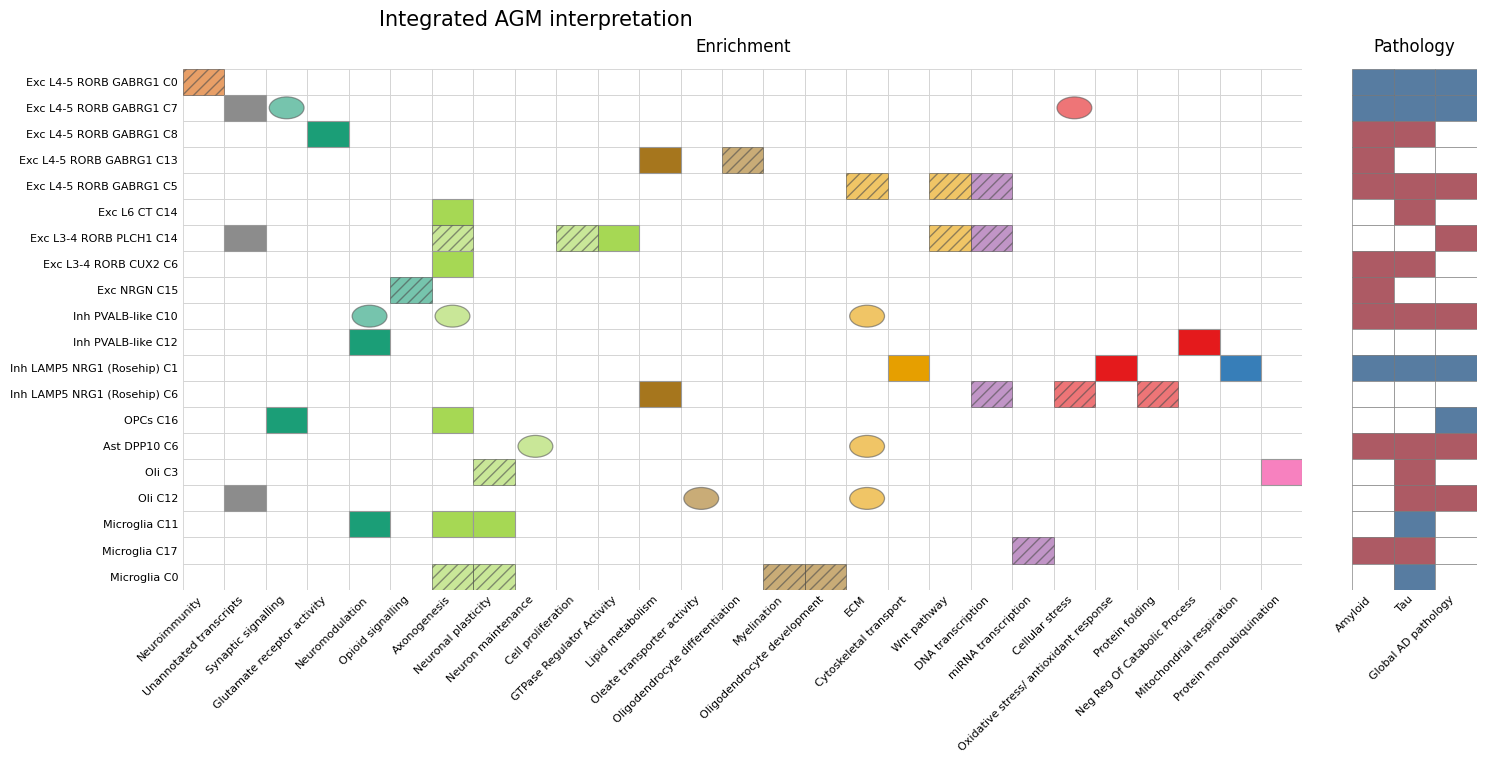

In [40]:
# Draw plot
n_rows = len(agm_order)
n_enrich = len(enrichment_categories)
n_path = len(pathology_categories)

fig = plt.figure(
    figsize=(
        n_enrich * 0.40 + n_path * 0.60 + 7,
        n_rows * 0.32 + 2,
    )
)

gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[n_enrich, n_path],
    wspace=0.08,
)

ax_enrich = fig.add_subplot(gs[0, 0])
ax_path = fig.add_subplot(gs[0, 1], sharey=ax_enrich)

axes = [ax_enrich, ax_path]


# 1. Draw empty white grids
for ax, n_cols in zip(axes, [n_enrich, 1, n_path]):
    for y in range(n_rows):
        for x in range(n_cols):
            ax.add_patch(
                patches.Rectangle(
                    (x, y),
                    1,
                    1,
                    facecolor="white",
                    edgecolor="0.82",
                    linewidth=0.6,
                )
            )

    ax.set_ylim(n_rows, 0)
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)


# 2. Fill enrichment panel
row_pos = {agm: i for i, agm in enumerate(agm_order)}
enrich_col_pos = {term: i for i, term in enumerate(enrichment_categories)}

for agm, items in enrichment.items():
    y = row_pos[agm]

    for term, support in items:
        if term not in enrich_col_pos:
            continue

        x = enrich_col_pos[term]
        draw_enrichment_cell(
            ax=ax_enrich,
            x=x,
            y=y,
            color=enrichment_colors[term],
            support=support,
        )


# 4. Fill pathology panel
path_col_pos = {cat: i for i, cat in enumerate(pathology_categories)}

for y, agm in enumerate(agm_order):
    agm_pathology = pathology.get(agm, {})

    for cat in pathology_categories:
        x = path_col_pos[cat]
        direction = agm_pathology.get(cat, "no")

        ax_path.add_patch(
            patches.Rectangle(
                (x, y),
                1,
                1,
                facecolor=direction_colors[direction],
                edgecolor="0.45",
                linewidth=0.4,
            )
        )


# 5. Format axes
ax_enrich.set_xlim(0, n_enrich)
ax_path.set_xlim(0, n_path)

ax_enrich.set_xticks([i + 0.5 for i in range(n_enrich)])
ax_enrich.set_xticklabels(
    enrichment_categories,
    rotation=45,
    ha="right",
    fontsize=8,
)



ax_path.set_xticks([i + 0.5 for i in range(n_path)])
ax_path.set_xticklabels(
    pathology_categories,
    rotation=45,
    ha="right",
    fontsize=8,
)

ax_enrich.set_yticks([i + 0.5 for i in range(n_rows)])
ax_enrich.set_yticklabels(agm_order, fontsize=8)

ax_path.tick_params(axis="y", labelleft=False)

ax_enrich.set_title("Enrichment", fontsize=12, pad=12)
ax_path.set_title("Pathology", fontsize=12, pad=12)

fig.suptitle("Integrated AGM interpretation", fontsize=15, y=0.97)

fig.subplots_adjust(
    left=0.32,
    right=0.98,
    bottom=0.28,
    top=0.90,
    wspace=0.08,
)
plt.savefig(Path(main_dir, "AGM_interpretation_heatmap.pdf"), dpi=300)
plt.show()

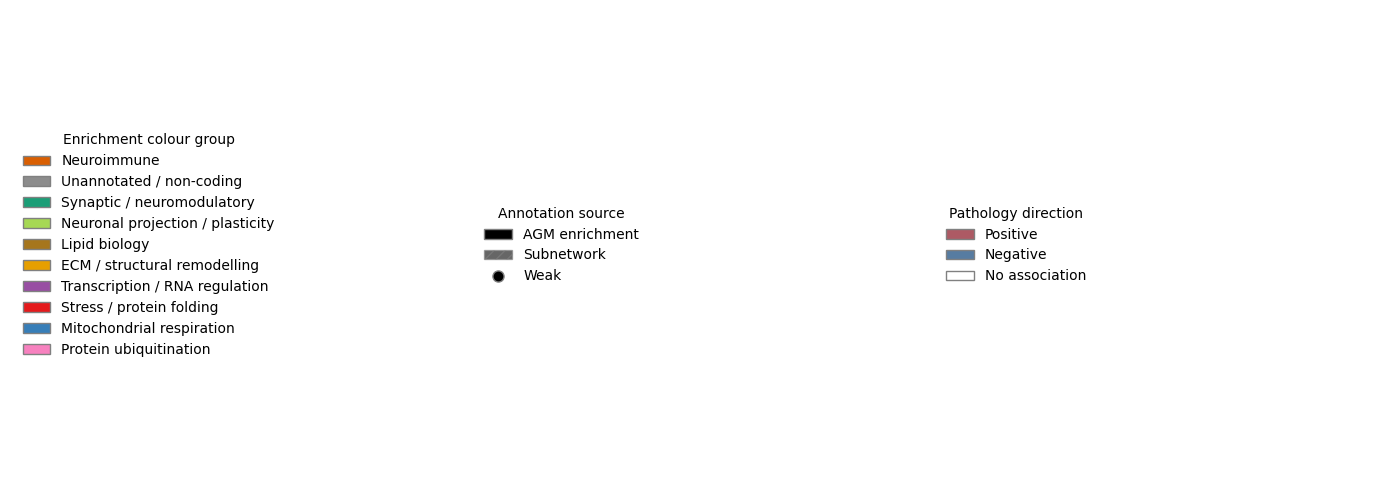

In [42]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Draw separate legend
enrichment_group_handles = [
    Patch(
        facecolor=group_colors[group],
        edgecolor="0.5",
        label=group,
    )
    for group in enrichment_colour_groups
]

support_handles = [
    Patch(
        facecolor="black",
        edgecolor="0.5",
        alpha=support_style["AGMenrich"]["alpha"],
        label="AGM enrichment",
    ),
    Patch(
        facecolor="black",
        edgecolor="0.5",
        alpha=support_style["Subnetwork"]["alpha"],
        hatch=support_style["Subnetwork"]["hatch"],
        label="Subnetwork",
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="white",
        markerfacecolor="black",
        markeredgecolor="0.5",
        markersize=8,
        linewidth=0,
        label="Weak",
    ),
]

direction_handles = [
    Patch(
        facecolor=direction_colors["positive"],
        edgecolor="0.5",
        label="Positive",
    ),
    Patch(
        facecolor=direction_colors["negative"],
        edgecolor="0.5",
        label="Negative",
    ),
    Patch(
        facecolor="white",
        edgecolor="0.5",
        label="No association",
    ),
]

fig_leg, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].legend(
    handles=enrichment_group_handles,
    title="Enrichment colour group",
    loc="center left",
    frameon=False,
)
axes[0].axis("off")

axes[1].legend(
    handles=support_handles,
    title="Annotation source",
    loc="center left",
    frameon=False,
)
axes[1].axis("off")

axes[2].legend(
    handles=direction_handles,
    title="Pathology direction",
    loc="center left",
    frameon=False,
)
axes[2].axis("off")

plt.tight_layout()
plt.savefig(Path(main_dir, "AGM_interpretation_legend.pdf"), dpi=300)
plt.show()